# ASSIGNMENT 3: BÀI TOÁN PHÂN LOẠI THỜI TIẾT BẰNG THƯ VIỆN SCIKIT-LEARN



In [ ]:
# Import các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import các module từ Scikit-Learn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Thiết lập cấu hình đồ họa hiển thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

print("Đã tải thành công các thư viện tiêu chuẩn và Scikit-Learn!")


Đã tải thành công các thư viện tiêu chuẩn và Scikit-Learn!


## Phần 1: Tải và Tiền Xử Lý Dữ Liệu Thời Tiết (Data Preprocessing)


In [ ]:
# 1. Đọc dữ liệu
df = pd.read_csv('weather_openmeteo.csv')

# 2. Trích xuất đặc trưng thời gian (Hour, Month) giống hệt File 1 & 2
df['Hour'] = df['Time'].apply(lambda t: int(str(t).split(':')[0]))
df['Date_dt'] = pd.to_datetime(df['Date'], errors='coerce')
df['Month'] = df['Date_dt'].dt.month

# 3. Gán nhãn Nhị phân (Target_Binary) - Giống hệt File 1 (Assignment 1)
rain_types = [
    'Light drizzle', 'Moderate drizzle', 'Dense drizzle',
    'Slight rain', 'Moderate rain', 'Heavy rain'
]
df['Target_Binary'] = df['Weather'].isin(rain_types).astype(int)

# 4. Gán nhãn Đa lớp (Target_Multi) - Giống hệt File 2 (Assignment 2)
def map_weather_to_class(weather_str):
    if weather_str in ['Clear sky', 'Mainly clear']:
        return 0  # Clear / Fair (Trời trong)
    elif weather_str in ['Partly cloudy', 'Overcast']:
        return 1  # Cloudy / Overcast (Mây / Âm u)
    elif weather_str in ['Light drizzle', 'Moderate drizzle', 'Dense drizzle']:
        return 2  # Drizzle (Mưa phùn)
    elif weather_str in ['Slight rain', 'Moderate rain', 'Heavy rain']:
        return 3  # Rain (Mưa rào / Mưa lớn)
    return -1

df['Target_Multi'] = df['Weather'].apply(map_weather_to_class)

# 5. Bộ 6 đặc trưng số & Phân chia Train/Test 80/20 với seed=42 (Giống hệt File 1 & 2)
feature_cols = ['Temperature', 'Humidity', 'Wind', 'Barometer', 'Hour', 'Month']
X = df[feature_cols].values
y_bin = df['Target_Binary'].values
y_multi = df['Target_Multi'].values

np.random.seed(42)
indices = np.random.permutation(len(X))
train_size = int(0.8 * len(X))

train_idx = indices[:train_size]
test_idx = indices[train_size:]

X_train, X_test = X[train_idx], X[test_idx]
y_bin_train, y_bin_test = y_bin[train_idx], y_bin[test_idx]
y_multi_train, y_multi_test = y_multi[train_idx], y_multi[test_idx]

# 6. Chuẩn hóa đặc trưng bằng StandardScaler của Scikit-Learn
# (Tương đương tuyệt đối với công thức Z-score (X - mean) / std trong NumPy)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Tổng số mẫu dữ liệu : {len(df):,} dòng")
print(f"Kích thước X_train    : {X_train_scaled.shape} ({train_size:,} mẫu)")
print(f"Kích thước X_test     : {X_test_scaled.shape} ({len(X_test_scaled):,} mẫu)")
print(f"Tỷ lệ nhãn nhị phân   : Không mưa = {np.mean(y_bin == 0)*100:.2f}%, Có mưa = {np.mean(y_bin == 1)*100:.2f}%")
print(f"Phân phối nhãn đa lớp : Clear: {np.sum(y_multi==0)}, Cloudy: {np.sum(y_multi==1)}, Drizzle: {np.sum(y_multi==2)}, Rain: {np.sum(y_multi==3)}")


Tổng số mẫu dữ liệu : 51,120 dòng
Kích thước X_train    : (40896, 6) (40,896 mẫu)
Kích thước X_test     : (10224, 6) (10,224 mẫu)
Tỷ lệ nhãn nhị phân   : Không mưa = 71.71%, Có mưa = 28.29%
Phân phối nhãn đa lớp : Clear: 10395, Cloudy: 26263, Drizzle: 11475, Rain: 2987


## Phần 2: Phân Loại Nhị Phân với Scikit-Learn Logistic Regression (Assignment 3.1)



KẾT QUẢ ĐÁNH GIÁ LOGISTIC REGRESSION (SCIKIT-LEARN - NHỊ PHÂN)
- Accuracy  (Độ chính xác) : 75.86%
- Precision (Độ chuẩn xác) : 59.58%
- Recall    (Độ nhạy)      : 34.89%
- F1-Score                 : 0.4401

Báo cáo phân loại chi tiết (Classification Report):
               precision    recall  f1-score   support

Không mưa (0)       0.79      0.91      0.85      7444
   Có mưa (1)       0.60      0.35      0.44      2780

     accuracy                           0.76     10224
    macro avg       0.69      0.63      0.64     10224
 weighted avg       0.74      0.76      0.74     10224



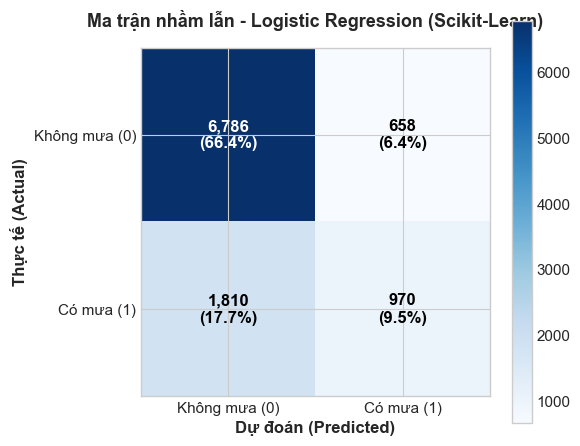

In [ ]:
# Khởi tạo và huấn luyện mô hình Logistic Regression của Scikit-Learn
sk_binary_model = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
sk_binary_model.fit(X_train_scaled, y_bin_train)

# Dự đoán trên tập kiểm tra
y_bin_pred = sk_binary_model.predict(X_test_scaled)

# Tính toán các chỉ số đánh giá
sk_bin_acc = accuracy_score(y_bin_test, y_bin_pred)
sk_bin_prec = precision_score(y_bin_test, y_bin_pred)
sk_bin_rec = recall_score(y_bin_test, y_bin_pred)
sk_bin_f1 = f1_score(y_bin_test, y_bin_pred)

print("=" * 60)
print("KẾT QUẢ ĐÁNH GIÁ LOGISTIC REGRESSION (SCIKIT-LEARN - NHỊ PHÂN)")
print("=" * 60)
print(f"- Accuracy  (Độ chính xác) : {sk_bin_acc * 100:.2f}%")
print(f"- Precision (Độ chuẩn xác) : {sk_bin_prec * 100:.2f}%")
print(f"- Recall    (Độ nhạy)      : {sk_bin_rec * 100:.2f}%")
print(f"- F1-Score                 : {sk_bin_f1:.4f}")
print("=" * 60)
print("\nBáo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_bin_test, y_bin_pred, target_names=['Không mưa (0)', 'Có mưa (1)']))

# Vẽ ma trận nhầm lẫn (Confusion Matrix)
cm_bin = confusion_matrix(y_bin_test, y_bin_pred)
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(cm_bin, cmap='Blues', interpolation='nearest')
fig.colorbar(cax)

for i in range(2):
    for j in range(2):
        val = cm_bin[i, j]
        pct = val / len(y_bin_test) * 100
        color = 'white' if val > cm_bin.max() / 2 else 'black'
        ax.text(j, i, f"{val:,}\n({pct:.1f}%)", ha='center', va='center',
                color=color, fontsize=12, fontweight='bold')

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Không mưa (0)', 'Có mưa (1)'], fontsize=11)
ax.set_yticklabels(['Không mưa (0)', 'Có mưa (1)'], fontsize=11)
ax.set_xlabel('Dự đoán (Predicted)', fontsize=12, fontweight='bold')
ax.set_ylabel('Thực tế (Actual)', fontsize=12, fontweight='bold')
ax.set_title('Ma trận nhầm lẫn - Logistic Regression (Scikit-Learn)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## Phần 3: Phân Loại Đa Lớp với Scikit-Learn Softmax Regression (Assignment 3.2)



KẾT QUẢ ĐÁNH GIÁ SOFTMAX REGRESSION (SCIKIT-LEARN - ĐA LỚP)
* Overall Accuracy (Độ chính xác tổng): 53.08%
* Macro F1-Score                       : 0.3141
* Weighted F1-Score                    : 0.4557

Báo cáo phân loại chi tiết 4 lớp thời tiết (Classification Report):
              precision    recall  f1-score   support

       Clear       0.41      0.05      0.10      2140
      Cloudy       0.56      0.87      0.68      5304
     Drizzle       0.43      0.31      0.36      2197
        Rain       0.35      0.08      0.12       583

    accuracy                           0.53     10224
   macro avg       0.44      0.33      0.31     10224
weighted avg       0.49      0.53      0.46     10224



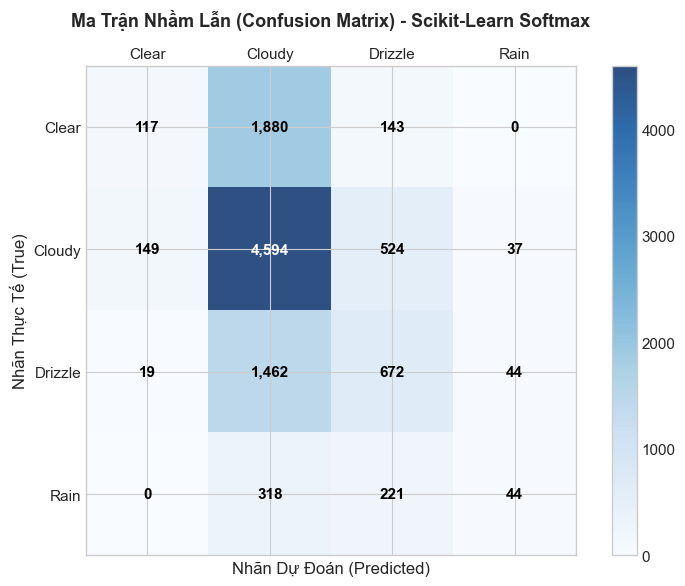

In [ ]:
# Khởi tạo và huấn luyện mô hình Scikit-Learn Softmax Regression
sk_multi_model = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
sk_multi_model.fit(X_train_scaled, y_multi_train)

# Dự đoán trên tập kiểm tra
y_multi_pred = sk_multi_model.predict(X_test_scaled)

# Tính toán các chỉ số tổng hợp
sk_multi_acc = accuracy_score(y_multi_test, y_multi_pred)
sk_multi_macro_f1 = f1_score(y_multi_test, y_multi_pred, average='macro')
sk_multi_weighted_f1 = f1_score(y_multi_test, y_multi_pred, average='weighted')

class_labels = ['Clear', 'Cloudy', 'Drizzle', 'Rain']

print("=" * 65)
print("KẾT QUẢ ĐÁNH GIÁ SOFTMAX REGRESSION (SCIKIT-LEARN - ĐA LỚP)")
print("=" * 65)
print(f"* Overall Accuracy (Độ chính xác tổng): {sk_multi_acc * 100:.2f}%")
print(f"* Macro F1-Score                       : {sk_multi_macro_f1:.4f}")
print(f"* Weighted F1-Score                    : {sk_multi_weighted_f1:.4f}")
print("=" * 65)
print("\nBáo cáo phân loại chi tiết 4 lớp thời tiết (Classification Report):")
print(classification_report(y_multi_test, y_multi_pred, target_names=class_labels))

# Vẽ ma trận nhầm lẫn 4x4 bằng Heatmap Matplotlib
cm_multi = confusion_matrix(y_multi_test, y_multi_pred)
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(cm_multi, cmap='Blues', alpha=0.85)
fig.colorbar(cax)

ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xticklabels(class_labels, fontsize=11)
ax.set_yticklabels(class_labels, fontsize=11)

for i in range(4):
    for j in range(4):
        val = cm_multi[i, j]
        color = 'white' if val > cm_multi.max() / 2 else 'black'
        ax.text(j, i, f"{val:,}", ha='center', va='center',
                color=color, fontsize=11, fontweight='bold')

plt.title('Ma Trận Nhầm Lẫn (Confusion Matrix) - Scikit-Learn Softmax', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Nhãn Dự Đoán (Predicted)', fontsize=12)
plt.ylabel('Nhãn Thực Tế (True)', fontsize=12)
plt.tight_layout()
plt.show()
